# Gjenkjenning av håndskrevne sifre med CNN (PyTorch)

Plan:
1. Oppsett og valg av enhet (CPU / Apple GPU)
2. Laste og se på MNIST-data
3. Definere et CNN
4. Treningsløkke
5. Evaluering

## Hva er et CNN?

Et **konvolusjonelt nevralt nettverk (CNN)** er en type nevralt nettverk laget for bilder. Det er grunnlaget for det meste av moderne bildegjenkjenning, fra ansiktsgjenkjenning på mobilen til medisinsk bildeanalyse.

### Problemet med vanlige nettverk
Et vanlig nevralt nettverk kobler hver piksel til hvert nevron i neste lag. For et 28×28-bilde gir det 784 innganger, og hvert nevron i første lag trenger 784 vekter. Nettverket vet heller ikke at piksler som ligger ved siden av hverandre, hører sammen. Et 7-tall som er flyttet tre piksler til høyre, ser for det ut som et helt annet bilde.

### Konvolusjon: små filtre som glir over bildet
Et CNN løser dette med **filtre**: små rutenett med vekter, her 3×3. Filteret glir over bildet, og på hver posisjon ganges de ni pikslene med de ni vektene og summeres. Resultatet er et nytt bilde, et *aktiveringskart*, som viser hvor i bildet filterets mønster finnes.

Ett filter kan for eksempel reagere på loddrette kanter, et annet på buer. Vektene i filtrene er ikke programmert for hånd. Nettverket lærer selv hvilke mønstre som er nyttige.

Dette gir to store fordeler:
- **Delte vekter:** Det samme filteret brukes over hele bildet, så et filter har bare 9 vekter (pluss én bias) uansett hvor stort bildet er.
- **Posisjonsuavhengighet:** Et mønster blir gjenkjent uansett hvor i bildet det dukker opp.

### Lagene i et CNN
- **Konvolusjonslag** (`Conv2d`) finner mønstre. Hvert lag har mange filtre, her 32 eller 64, og gir ett aktiveringskart per filter. Lagene bygger på hverandre: de første finner enkle kanter og streker, de senere kombinerer dem til løkker, hjørner og kryss, altså de delene sifre er bygget opp av.
- **ReLU** setter negative verdier til 0. Uten et slikt ikke-lineært steg ville alle lagene til sammen bare tilsvare én enkel lineær beregning.
- **BatchNorm** normaliserer verdiene mellom lagene, slik at treningen blir raskere og mer stabil.
- **Pooling** (`MaxPool2d`) krymper bildet til halv størrelse ved å beholde den største verdien i hvert 2×2-område. Det reduserer regnearbeidet og gjør modellen mindre følsom for små forskyvninger.
- **Fullt koblede lag** (`Linear`) kommer helt til slutt. Aktiveringskartene flates ut til én lang liste, og lagene avgjør ut fra hvilke mønstre som er funnet hvilket siffer det er.
- **Dropout** slår tilfeldig av en del av nevronene under trening, slik at modellen ikke blir for avhengig av enkeltnevroner og pugger treningsdataene.

### Fra bilde til svar i denne modellen
1. Inndata: et gråtonebilde på 1 × 28 × 28.
2. To konvolusjonslag med 32 filtre, deretter pooling → 32 × 14 × 14.
3. To konvolusjonslag med 64 filtre, deretter pooling → 64 × 7 × 7.
4. Flatten → 3136 tall → fullt koblet lag med 128 nevroner → 10 utganger, ett per siffer 0–9.

Den største utgangen er modellens gjetning. Softmax kan gjøre de ti tallene om til sannsynligheter som summerer seg til 100 %.

### Trening
Under treningen får modellen bilder sammen med fasiten. **Tapsfunksjonen** (cross-entropy) måler hvor feil gjetningen er. **Tilbakepropagering** regner ut hvordan hver vekt bør endres for å gjøre feilen mindre, og **optimalisereren** (Adam) justerer vektene litt i den retningen. Etter mange runder gjennom de 60 000 treningsbildene har filtrene lært mønstrene som skiller sifrene fra hverandre.


## 1. Oppsett

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Bruk Apple-GPU (MPS) hvis tilgjengelig, ellers CPU
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch", torch.__version__, "- enhet:", device)

PyTorch 2.15.0 - enhet: mps


## 2. Laste MNIST

MNIST består av 28×28 gråtonebilder av sifre (0–9): 60 000 til trening og 10 000 til test.

- `ToTensor()` gjør bildet om til en tensor med form `[1, 28, 28]` og verdier mellom 0 og 1.
- `Normalize()` trekker fra gjennomsnittet og deler på standardavviket, noe som gjør treningen mer stabil.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),  # gjennomsnitt og standardavvik for MNIST
])

train_data = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_data = datasets.MNIST(root="data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=1000)

print(len(train_data), "treningsbilder,", len(test_data), "testbilder")

60000 treningsbilder, 10000 testbilder


images: torch.Size([64, 1, 28, 28])
labels: torch.Size([64])


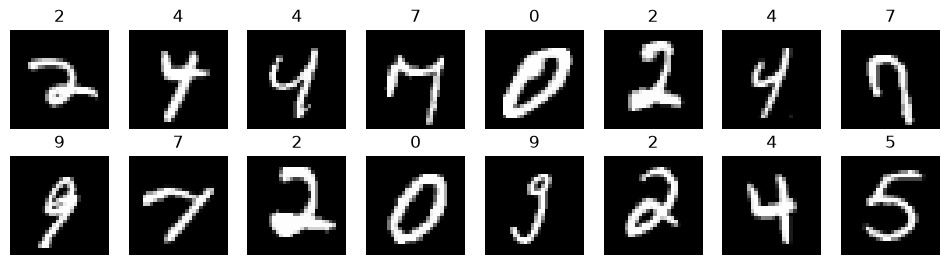

In [3]:
# Se på én batch: hvilken form har dataene?
images, labels = next(iter(train_loader))
print("images:", images.shape)  # [batch, kanaler, høyde, bredde]
print("labels:", labels.shape)

# Visualiser noen av bildene
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for ax, img, label in zip(axes.flat, images, labels):
    ax.imshow(img.squeeze(), cmap="gray")
    ax.set_title(label.item())
    ax.axis("off")
plt.show()

## 3. Definere et CNN



In [4]:
loaders = {
    "train": DataLoader(train_data, 
                        batch_size=100, 
                        shuffle=True,
                        num_workers=0),
    "test": DataLoader(test_data, 
                       batch_size=100,
                       shuffle=True,
                       num_workers=0),
}

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 32 × 14 × 14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                   # 64 × 7 × 7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))


# class CNN(nn.Module):
#     def __init__(self):
#         super(CNN, self).__init__()
        
#         self.conv1 = nn.Conv2d(1, 10, kernel_size=5)
#         self.conv2 = nn.Conv2d(10, 20, kernel_size=5)
#         self.conv2_drop = nn.Dropout2d()
#         # self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
#         self.fc1 = nn.Linear(320, 50)
#         self.fc2 = nn.Linear(50, 10)

#     def forward(self, x):
#         x = F.relu(F.max_pool2d(self.conv1(x), 2))
#         x = F.relu(F.max_pool2d(self.conv2_drop(self.conv2(x)), 2))
#         x = x.view(-1, 320)  # Flatten
#         x = F.relu(self.fc1(x))
#         x = F.dropout(x, training=self.training)
#         x = self.fc2(x)
        
#         return x  # Output probabilities for each class

## 4. Trening


In [5]:
model = CNN().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

def train(epoch):
    model.train()
    for batch_idx, (data, target) in enumerate(loaders["train"]):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = loss_fn(output, target)
        loss.backward()
        optimizer.step()
        
        if batch_idx % 20 == 0:
            print(f"Train Epoch: {epoch} [{batch_idx * len(data)}/{len(loaders['train'].dataset)} "
                  f"({100. * batch_idx / len(loaders['train']):.0f}%)]\tLoss: {loss.item():.6f}")

def test():
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in loaders["test"]:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += loss_fn(output, target).item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(loaders["test"].dataset)

    print(f"\nTest set: Average loss: {test_loss:.4f}, Accuracy: {correct}/{len(loaders['test'].dataset)} "
          f"({100. * correct / len(loaders['test'].dataset):.0f}%)\n")

for epoch in range(1, 11):
    train(epoch)
    test()

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.359611
Train Epoch: 1 [2000/60000 (3%)]	Loss: 0.603161
Train Epoch: 1 [4000/60000 (7%)]	Loss: 0.454489
Train Epoch: 1 [6000/60000 (10%)]	Loss: 0.207462
Train Epoch: 1 [8000/60000 (13%)]	Loss: 0.202627
Train Epoch: 1 [10000/60000 (17%)]	Loss: 0.125300
Train Epoch: 1 [12000/60000 (20%)]	Loss: 0.089301
Train Epoch: 1 [14000/60000 (23%)]	Loss: 0.065752
Train Epoch: 1 [16000/60000 (27%)]	Loss: 0.079541
Train Epoch: 1 [18000/60000 (30%)]	Loss: 0.079429
Train Epoch: 1 [20000/60000 (33%)]	Loss: 0.081486
Train Epoch: 1 [22000/60000 (37%)]	Loss: 0.083302
Train Epoch: 1 [24000/60000 (40%)]	Loss: 0.133225
Train Epoch: 1 [26000/60000 (43%)]	Loss: 0.164700
Train Epoch: 1 [28000/60000 (47%)]	Loss: 0.089046
Train Epoch: 1 [30000/60000 (50%)]	Loss: 0.040445
Train Epoch: 1 [32000/60000 (53%)]	Loss: 0.016582
Train Epoch: 1 [34000/60000 (57%)]	Loss: 0.011250
Train Epoch: 1 [36000/60000 (60%)]	Loss: 0.081245
Train Epoch: 1 [38000/60000 (63%)]	Loss: 0.052878
Train Epoch

In [6]:
torch.save(model.state_dict(), "mnist_cnn.pt")

## Eksport til nettsiden (ONNX)

Nettsiden i `docs/` kjører modellen direkte i nettleseren med ONNX Runtime Web. Vi pakker modellen inn slik at normalisering og softmax skjer inne i modellen. Da sender nettsiden bare inn et 28×28-bilde med verdier 0–1 og får sannsynligheter tilbake.

Kjør cellen under på nytt hver gang du har trent en ny modell.

In [7]:
import copy
import os


class DigitModelForWeb(nn.Module):
    """Modellen + normalisering + softmax, klar for nettleseren."""
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):                 # x: [1, 1, 28, 28], verdier 0–1, hvitt tall på svart
        x = (x - 0.1307) / 0.3081         # samme normalisering som i treningen
        return F.softmax(self.model(x), dim=1)


# Kopier til CPU, slik at modellen du trener med blir værende på GPU-en
web_model = DigitModelForWeb(copy.deepcopy(model).cpu()).eval()

os.makedirs("docs", exist_ok=True)
torch.onnx.export(
    web_model,
    (torch.rand(1, 1, 28, 28),),
    "docs/mnist_cnn.onnx",
    input_names=["image"],
    output_names=["probs"],
    external_data=False,                  # alle vektene i én fil
)
print("Lagret docs/mnist_cnn.onnx,", os.path.getsize("docs/mnist_cnn.onnx") // 1024, "kB")

[torch.onnx] Obtain model graph for `DigitModelForWeb([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DigitModelForWeb([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Lagret docs/mnist_cnn.onnx, 1855 kB


## 5. Evaluering

Kjør modellen på testdataene med `model.eval()` og `torch.no_grad()`, og regn ut nøyaktigheten. Målet er over 98 %.

Nøyaktighet: 99.38 % (62 feil av 10000)

Forvekslingsmatrise (rad = fasit, kolonne = gjetning):
tensor([[ 979,    0,    0,    0,    0,    0,    0,    0,    0,    1],
        [   0, 1132,    1,    1,    0,    0,    0,    1,    0,    0],
        [   0,    0, 1032,    0,    0,    0,    0,    0,    0,    0],
        [   0,    0,    0, 1008,    0,    1,    0,    0,    1,    0],
        [   0,    0,    0,    0,  973,    0,    0,    0,    2,    7],
        [   0,    1,    0,    5,    0,  885,    1,    0,    0,    0],
        [   3,    1,    0,    0,    1,    0,  952,    0,    1,    0],
        [   0,    2,    8,    0,    0,    0,    0, 1014,    1,    3],
        [   1,    0,    2,    1,    0,    0,    0,    0,  969,    1],
        [   1,    0,    0,    2,    5,    4,    0,    0,    3,  994]])
Siffer 0: 99.90 %
Siffer 1: 99.74 %
Siffer 2: 100.00 %
Siffer 3: 99.80 %
Siffer 4: 99.08 %
Siffer 5: 99.22 %
Siffer 6: 99.37 %
Siffer 7: 98.64 %
Siffer 8: 99.49 %
Siffer 9: 98.51 %


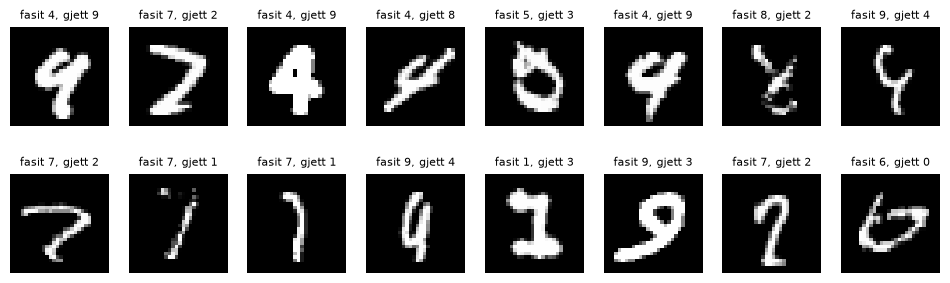

In [8]:
model.eval()
all_preds, all_labels, all_images = [], [], []
with torch.no_grad():  # ingen gradienter: raskere og bruker mindre minne
    for data, target in loaders["test"]:
        output = model(data.to(device))
        all_preds.append(output.argmax(dim=1).cpu())
        all_labels.append(target)
        all_images.append(data)

preds = torch.cat(all_preds)
labels = torch.cat(all_labels)
images = torch.cat(all_images)

# 1. Nøyaktighet med desimaler
correct = (preds == labels).sum().item()
print(f"Nøyaktighet: {100 * correct / len(labels):.2f} % ({len(labels) - correct} feil av {len(labels)})")

# 2. Forvekslingsmatrise: rad = riktig siffer, kolonne = modellens gjetning
confusion = torch.zeros(10, 10, dtype=torch.int64)
for t, p in zip(labels, preds):
    confusion[t, p] += 1
print("\nForvekslingsmatrise (rad = fasit, kolonne = gjetning):")
print(confusion)

# 3. Nøyaktighet per siffer
for digit in range(10):
    print(f"Siffer {digit}: {100 * confusion[digit, digit] / confusion[digit].sum():.2f} %")

# 4. Vis noen av bildene modellen bommet på
wrong = (preds != labels).nonzero().squeeze()
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, i in zip(axes.flat, wrong[:16]):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"fasit {labels[i]}, gjett {preds[i]}", fontsize=8)
    ax.axis("off")
plt.show()
